# IDS_ML_Project — corrected version (v5)

**Design and Implementation of a Machine Learning-Based Intrusion Detection System**
Brahim EL HANATI · Master SDIA, ENSET Mohammedia

---

## v4 — remarks from progress report n°1

| # | Remark | How it is handled |
|---|--------|-------------------|
| 1 | Deduplication was a no-op (`id` dropped afterwards) | §3 — dedup on feature columns only |
| 2 | No EDA | §2 — full section, including train↔test overlap |
| 3 | Class imbalance not addressed | §7 — `scale_pos_weight` tested at 1.05 and 3, reported, **not adopted**: it moves the operating point without changing ROC-AUC, and the threshold is chosen explicitly in §10 |
| 4 | Models compared at threshold 0.50 only | §8 — comparison at fixed FPR (1%, 5%, 10%) |
| 5 | No naive baseline | §6 — `DummyClassifier`, accuracy floor 0.5128 |
| 6 | No tuning, no latency | §9 tuning · §8 measured inference latency |
| 7 | Error analysis only at aggregate level | §14 — FN by attack category, FP by protocol/service |
| 8 | SHAP alone, `sttl` never questioned | §12 permutation importance · §13 ablation of `sttl` |
| 9 | "probability" never calibrated | §11 — calibration curve + Brier score |
| 10 | Multiclass mode did not work | §16 — hierarchical binary → multiclass |
| 11 | `prep` shared and refitted across pipelines | `make_prep()` returns a fresh object every call |

## v5 — remarks from the supervisor's review of v4

| # | Remark | How it is handled |
|---|--------|-------------------|
| 12 | The FPR degradation was attributed to distribution shift as if it were the established mechanism | §15 — restated as a plausible contributing factor. The final model is refitted on train + validation, so dataset shift and score shift cannot be separated by this design; both are stated |
| 13 | No evidence distinguishing a change in traffic mix from a change in behaviour | §15.1 — KS diagnostic on the score and feature distributions, per connection state |
| 14 | Stage-2 model selected on macro-F1, which lets a common class mask a rare one | §16 — selection on balanced accuracy, with macro-F1 reported as a control |

**Experimental protocol.** The official test set stays sealed until §15. Every choice
(model, hyperparameters, threshold, imbalance handling) is made on the validation set
carved out of the official training set. §15 is the only evaluation on the test set.

## 0. Setup and data loading

In [1]:

from google.colab import drive
drive.mount('/content/drive')

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

DATA = "/content/drive/MyDrive/data"          # <-- Colab
# DATA = "./data"                             # <-- local run

train_raw = pd.read_csv(f"{DATA}/UNSW_NB15_training-set.csv")
test_raw = pd.read_csv(f"{DATA}/UNSW_NB15_testing-set.csv")
print("train:", train_raw.shape, " test:", test_raw.shape)

Mounted at /content/drive
train: (175341, 45)  test: (82332, 45)


## 1. Configuration

The notebook switches. `DROP_DUPLICATES` triggers the **robustness variant** studied in
§3; `RUN_TUNING` and `RUN_MULTICLASS` allow a lighter re-run when only verifying the code.

In [2]:
SEED = 42
DROP_DUPLICATES = True      # True = deduplicated variant (see §3 for the measured effect)
RUN_TUNING = True           # XGBoost hyperparameter search (§9)
RUN_MULTICLASS = True       # hierarchical attack-category classification (§16)
N_ITER_SEARCH = 12          # random search draws
FPR_BUDGET = 0.05           # chosen SOC policy: FPR <= 5%

LABEL_COL = "label"
CAT_COL = "attack_cat"
ID_COL = "id"

np.random.seed(SEED)

## 2. Exploratory data analysis (EDA)

This section was missing entirely. It documents what the data actually contains **before**
any modelling, and above all it measures the two things that condition the validity of
everything that follows: the true duplicate rate and the **train/test overlap**.

### 2.1. Class distribution

--- TRAIN — 175,341 observations
    normal (0) :  56,000  (31.9%)
    attack (1) : 119,341  (68.1%)
    normal:attack ratio = 1:2.13
--- TEST — 82,332 observations
    normal (0) :  37,000  (44.9%)
    attack (1) :  45,332  (55.1%)
    normal:attack ratio = 1:1.23

Breakdown by attack category:
                train   test  train_%  test_%
attack_cat                                   
Normal          56000  37000    31.94   44.94
Generic         40000  18871    22.81   22.92
Exploits        33393  11132    19.04   13.52
Fuzzers         18184   6062    10.37    7.36
DoS             12264   4089     6.99    4.97
Reconnaissance  10491   3496     5.98    4.25
Analysis         2000    677     1.14    0.82
Backdoor         1746    583     1.00    0.71
Shellcode        1133    378     0.65    0.46
Worms             130     44     0.07    0.05


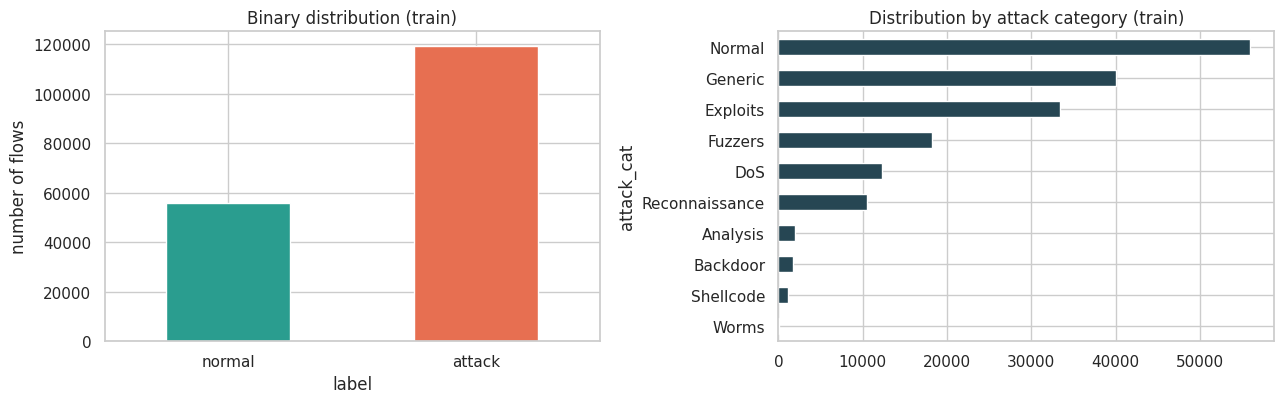


Reading: the binary imbalance is moderate on this split, but the multiclass
imbalance is severe — it is what will drive the choices made in §16.


In [3]:
def class_report(df, name):
    n = len(df)
    bin_counts = df[LABEL_COL].value_counts().sort_index()
    print(f"--- {name} — {n:,} observations")
    print(f"    normal (0) : {bin_counts.get(0, 0):>7,}  ({bin_counts.get(0, 0)/n:.1%})")
    print(f"    attack (1) : {bin_counts.get(1, 0):>7,}  ({bin_counts.get(1, 0)/n:.1%})")
    ratio = bin_counts.get(0, 0) / max(bin_counts.get(1, 1), 1)
    print(f"    normal:attack ratio = 1:{1/ratio:.2f}" if ratio < 1 else
          f"    normal:attack ratio = {ratio:.2f}:1")
    return df[CAT_COL].value_counts()


cat_tr = class_report(train_raw, "TRAIN")
cat_te = class_report(test_raw, "TEST")

cat_tbl = pd.DataFrame({"train": cat_tr, "test": cat_te}).fillna(0).astype(int)
cat_tbl["train_%"] = (cat_tbl["train"] / cat_tbl["train"].sum() * 100).round(2)
cat_tbl["test_%"] = (cat_tbl["test"] / cat_tbl["test"].sum() * 100).round(2)
cat_tbl = cat_tbl.sort_values("train", ascending=False)
print("\nBreakdown by attack category:")
print(cat_tbl)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
train_raw[LABEL_COL].value_counts().sort_index().plot(
    kind="bar", ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_xticklabels(["normal", "attack"], rotation=0)
ax[0].set_title("Binary distribution (train)")
ax[0].set_ylabel("number of flows")
cat_tbl["train"].plot(kind="barh", ax=ax[1], color="#264653")
ax[1].set_title("Distribution by attack category (train)")
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

print("\nReading: the binary imbalance is moderate on this split, but the multiclass")
print("imbalance is severe — it is what will drive the choices made in §16.")

### 2.2. Data quality: missing values, infinities, constant columns

In [4]:
def quality_report(df, name):
    n = len(df)
    miss = df.isna().sum()
    miss = miss[miss > 0]
    num = df.select_dtypes("number")
    inf = np.isinf(num).sum()
    inf = inf[inf > 0]
    const = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    neg = {c: int((num[c] < 0).sum()) for c in num.columns if (num[c] < 0).any()}
    print(f"--- {name}")
    print(f"    missing values   : {'none' if miss.empty else miss.to_dict()}")
    print(f"    infinite values  : {'none' if inf.empty else inf.to_dict()}")
    print(f"    constant columns : {const if const else 'none'}")
    print(f"    columns with negative values : {neg if neg else 'none'}")
    return neg


neg_train = quality_report(train_raw, "TRAIN")
neg_test = quality_report(test_raw, "TEST")

print("\nWhy this negative-value check: preprocessing applies")
print("np.log1p(np.clip(x, 0, None)). Any negative value would be silently crushed to 0.")
if neg_train:
    print("WARNING — some columns contain negatives, the clip is NOT neutral:")
    print(" ", list(neg_train))
else:
    print("No negative column: the clip is destructive-free here. Justified.")

--- TRAIN
    missing values   : none
    infinite values  : none
    constant columns : none
    columns with negative values : none
--- TEST
    missing values   : none
    infinite values  : none
    constant columns : none
    columns with negative values : none

Why this negative-value check: preprocessing applies
np.log1p(np.clip(x, 0, None)). Any negative value would be silently crushed to 0.
No negative column: the clip is destructive-free here. Justified.


### 2.3. Duplicates — with and without the `id` column

This is the point the analysis flagged. `drop_duplicates()` applied **before** dropping
`id` removes nothing, since every row carries a unique identifier. We measure the gap
between the two ways of counting.

In [5]:
feature_cols_all = [c for c in train_raw.columns if c not in (ID_COL, LABEL_COL, CAT_COL)]

for df, name in [(train_raw, "TRAIN"), (test_raw, "TEST")]:
    with_id = int(df.duplicated().sum())
    without_id = int(df.duplicated(subset=feature_cols_all).sum())
    print(f"--- {name}")
    print(f"    duplicates counting `id` : {with_id:,}   <- what the old code counted")
    print(f"    duplicates on feature columns : {without_id:,}  ({without_id/len(df):.2%})")

--- TRAIN
    duplicates counting `id` : 0   <- what the old code counted
    duplicates on feature columns : 74,301  (42.38%)
--- TEST
    duplicates counting `id` : 0   <- what the old code counted
    duplicates on feature columns : 28,386  (34.48%)


### 2.4. Train/test overlap

If identical observations appear on both sides, the performance measured on the test set
is optimistic. This check did not exist.

In [6]:
def row_hash(df, cols):
    return pd.util.hash_pandas_object(df[cols].astype(str).agg("|".join, axis=1), index=False)


h_tr = set(row_hash(train_raw, feature_cols_all))
h_te = row_hash(test_raw, feature_cols_all)
overlap_mask = h_te.isin(h_tr).to_numpy()
n_overlap = int(overlap_mask.sum())

print(f"Test flows also present in train: {n_overlap:,} / {len(test_raw):,} "
      f"({n_overlap/len(test_raw):.2%})")
if n_overlap:
    print("These flows are tracked separately in the final evaluation (§15): performance on")
    print("'already seen' and 'never seen' flows is reported distinctly.")
else:
    print("No overlap: the test set is genuinely disjoint from train.")

Test flows also present in train: 8,541 / 82,332 (10.37%)
These flows are tracked separately in the final evaluation (§15): performance on
'already seen' and 'never seen' flows is reported distinctly.


### 2.5. Categorical cardinality and train/test drift

In [7]:
CAT_FEATURES = ["proto", "service", "state"]
for c in CAT_FEATURES:
    only_test = set(test_raw[c].unique()) - set(train_raw[c].unique())
    print(f"{c:<9} train={train_raw[c].nunique():>3} levels  test={test_raw[c].nunique():>3}"
          f"  |  levels seen only in test: {sorted(only_test) if only_test else 'none'}")

print("\nThe OneHotEncoder uses handle_unknown='ignore': unseen levels are encoded as zeros")
print("instead of making prediction fail.")

proto     train=133 levels  test=131  |  levels seen only in test: none
service   train= 13 levels  test= 13  |  levels seen only in test: none
state     train=  9 levels  test=  7  |  levels seen only in test: ['ACC', 'CLO']

The OneHotEncoder uses handle_unknown='ignore': unseen levels are encoded as zeros
instead of making prediction fail.


### 2.6. Train vs test distribution comparison

A marked gap would signal *dataset shift* and invalidate the assumption that the test set
measures generalisation over the same population.

In [8]:
num_feats = [c for c in train_raw[feature_cols_all].select_dtypes("number").columns]
shift = pd.DataFrame({
    "train_median": train_raw[num_feats].median(),
    "test_median": test_raw[num_feats].median(),
    "train_mean": train_raw[num_feats].mean(),
    "test_mean": test_raw[num_feats].mean(),
})
shift["median_rel_gap"] = (
    (shift["test_median"] - shift["train_median"]).abs()
    / shift["train_median"].abs().replace(0, np.nan)
)
print("The 10 most shifted variables between train and test (relative median gap):")
print(shift.sort_values("median_rel_gap", ascending=False).head(10).round(3))

The 10 most shifted variables between train and test (relative median gap):
            train_median  test_median    train_mean     test_mean  median_rel_gap
dur                0.002        0.014  1.359000e+00  1.007000e+00           7.937
spkts              2.000        6.000  2.029900e+01  1.866600e+01           2.000
sinpkt             0.280        0.558  9.859770e+02  7.553940e+02           0.995
dinpkt             0.006        0.010  8.821600e+01  1.217010e+02           0.667
dload           1447.023     2112.951  6.712056e+05  6.305470e+05           0.460
sload         879674.750   577003.219  7.345403e+07  6.454902e+07           0.344
ct_srv_dst         4.000        5.000  9.101000e+00  9.164000e+00           0.250
sbytes           430.000      534.000  8.844844e+03  7.993908e+03           0.242
rate            3225.807     2650.177  9.540619e+04  8.241089e+04           0.178
smean             73.000       65.000  1.367520e+02  1.395290e+02           0.110


## 3. Cleaning — deduplication fixed

**The fix.** The old code called `train.drop_duplicates()` while `id` was still present:
not a single row was removed. We now deduplicate explicitly on the feature columns. We
then measure the effect of the variant on performance rather than enabling it blindly.

In [9]:
def deduplicate(df, name):
    before = len(df)
    out = df.drop_duplicates(subset=feature_cols_all).reset_index(drop=True)
    print(f"{name}: {before:,} -> {len(out):,} rows  ({before - len(out):,} duplicates removed)")
    return out


train_work = train_raw.copy()
test_work = test_raw.copy()

if DROP_DUPLICATES:
    print("Deduplicated variant ACTIVE (dedup on feature columns, `id` excluded):")
    train_work = deduplicate(train_work, "train")
    # The test set is NOT deduplicated: it stands for traffic as it reaches the SOC.
    print("test: left intact — it simulates real traffic, duplicates included.")
else:
    print("Baseline variant: duplicates kept.")

Deduplicated variant ACTIVE (dedup on feature columns, `id` excluded):
train: 175,341 -> 101,040 rows  (74,301 duplicates removed)
test: left intact — it simulates real traffic, duplicates included.


### 3.1. Cleaning parameters — learned on train only

In [10]:
def fit_prep_params(df):
    """Learn cleaning parameters from the TRAIN set only (leakage-free)."""
    p = {}
    num = df.drop(columns=[ID_COL, CAT_COL, LABEL_COL], errors="ignore").select_dtypes("number")
    corr = num.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
    p["drop_redundant"] = [c for c in upper.columns if (upper[c] > 0.95).any()]
    # keep track of WHICH variable correlates with WHICH, to justify it in the report
    p["redundant_pairs"] = [
        (r, c, round(float(upper.loc[r, c]), 3))
        for c in upper.columns for r in upper.index
        if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > 0.95
    ]
    p["keep_proto"] = df["proto"].value_counts().head(10).index.tolist()
    return p


def apply_prep(df, p, drop_redundant=True):
    df = df.copy()
    df.drop(columns=[ID_COL], inplace=True, errors="ignore")
    df["service"] = df["service"].replace("-", "none")
    df["proto"] = np.where(df["proto"].isin(p["keep_proto"]), df["proto"], "other")
    if drop_redundant:
        df.drop(columns=p["drop_redundant"], inplace=True, errors="ignore")
    return df


params = fit_prep_params(train_work)
train_c = apply_prep(train_work, params)
test_c = apply_prep(test_work, params)

print("Variables dropped for redundancy (corr > 0.95):", params["drop_redundant"])
print("\nResponsible pairs — cite these in the report instead of relying on column order:")
for a, b, v in params["redundant_pairs"][:15]:
    print(f"    {a:<20} ~ {b:<20} r={v}")
print("\nProtocols kept:", params["keep_proto"])
print("Methodological caveat: a high correlation does not make a variable useless in")
print("cybersecurity. §13 (ablation) tests the real effect of these removals.")

Variables dropped for redundancy (corr > 0.95): ['sbytes', 'dbytes', 'sloss', 'dloss', 'dwin', 'ct_ftp_cmd']

Responsible pairs — cite these in the report instead of relying on column order:
    spkts                ~ sbytes               r=0.967
    dpkts                ~ dbytes               r=0.971
    spkts                ~ sloss                r=0.975
    sbytes               ~ sloss                r=0.997
    dpkts                ~ dloss                r=0.977
    dbytes               ~ dloss                r=0.997
    swin                 ~ dwin                 r=0.984
    is_ftp_login         ~ ct_ftp_cmd           r=1.0

Protocols kept: ['tcp', 'udp', 'arp', 'unas', 'ospf', 'sctp', 'any', 'igmp', 'icmp', 'ipv6']
Methodological caveat: a high correlation does not make a variable useless in
cybersecurity. §13 (ablation) tests the real effect of these removals.


## 4. Splitting — inner train / validation / sealed test

The split is done on the *dataframe* rather than on `X` alone, so that `attack_cat` stays
aligned with the validation set: this is required for the per-category error analysis
(§14).

In [11]:
from sklearn.model_selection import train_test_split

tr_df, val_df = train_test_split(
    train_c, test_size=0.20, stratify=train_c[LABEL_COL], random_state=SEED)

DROP_TARGETS = [CAT_COL, LABEL_COL]
X_tr = tr_df.drop(columns=DROP_TARGETS)
y_tr = tr_df[LABEL_COL].to_numpy()
X_val = val_df.drop(columns=DROP_TARGETS)
y_val = val_df[LABEL_COL].to_numpy()
cat_val = val_df[CAT_COL].to_numpy()

# full official train set — used only for the final refit (§15)
X_train_full = train_c.drop(columns=DROP_TARGETS)
y_train_full = train_c[LABEL_COL].to_numpy()

# SEALED TEST — appears only in §15
X_test = test_c.drop(columns=DROP_TARGETS)
y_test = test_c[LABEL_COL].to_numpy()
cat_test = test_c[CAT_COL].to_numpy()

cat_cols = [c for c in CAT_FEATURES if c in X_tr.columns]
num_cols = [c for c in X_tr.columns if c not in cat_cols]

print(f"inner train : {X_tr.shape}")
print(f"validation  : {X_val.shape}   <- every choice is made here")
print(f"full train  : {X_train_full.shape}   <- final refit")
print(f"SEALED test : {X_test.shape}   <- a single evaluation, §15")
print(f"\n{len(num_cols)} numeric variables, {len(cat_cols)} categorical")

inner train : (80832, 36)
validation  : (20208, 36)   <- every choice is made here
full train  : (101040, 36)   <- final refit
SEALED test : (82332, 36)   <- a single evaluation, §15

33 numeric variables, 3 categorical


## 5. Preprocessing pipeline

**Fix n°11.** `make_prep()` returns a fresh object on every call. In the previous version a
single `ColumnTransformer` was shared by all pipelines and refitted on every `.fit()`:
models trained earlier silently ended up attached to a preprocessing step fitted on other
data.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer


def log1p_clip(x):
    """Named (not a lambda) so it stays picklable by joblib."""
    return np.log1p(np.clip(x, 0, None))


def make_prep(numeric=None, categorical=None):
    numeric = num_cols if numeric is None else numeric
    categorical = cat_cols if categorical is None else categorical
    numeric_pipe = Pipeline([
        ("log", FunctionTransformer(log1p_clip, feature_names_out="one-to-one")),
        ("scale", RobustScaler()),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])


def make_pipe(model, numeric=None, categorical=None):
    return Pipeline([("prep", make_prep(numeric, categorical)), ("model", model)])

## 6. Naive baseline — quantifying the real gain

Without a trivial reference point, an accuracy of 0.86 means nothing. The
`DummyClassifier` gives the floor: what a system that never looks at the data achieves.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)


def soc_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, proba) if len(np.unique(y_true)) > 1 else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else 0.0,
        "FNR": fn / (fn + tp) if (fn + tp) else 0.0,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }


dummy_rows = []
for strat in ["most_frequent", "stratified", "prior"]:
    d = make_pipe(DummyClassifier(strategy=strat, random_state=SEED))
    d.fit(X_tr, y_tr)
    pr = d.predict_proba(X_val)[:, 1]
    m = soc_metrics(y_val, pr)
    dummy_rows.append({"baseline": strat, **{k: m[k] for k in
                       ("accuracy", "precision", "recall", "F1", "ROC_AUC", "FPR")}})

baseline_tbl = pd.DataFrame(dummy_rows).set_index("baseline").round(4)
print("Naive baselines (validation):")
print(baseline_tbl)
print(f"\nAccuracy floor to beat: {baseline_tbl['accuracy'].max():.4f}")
print("Any performance must be read as a gap above this floor, not in absolute terms.")

Naive baselines (validation):
               accuracy  precision  recall      F1  ROC_AUC     FPR
baseline                                                           
most_frequent    0.5128     0.0000  0.0000  0.0000    0.500  0.0000
stratified       0.5044     0.4913  0.4884  0.4898    0.504  0.4805
prior            0.5128     0.0000  0.0000  0.0000    0.500  0.0000

Accuracy floor to beat: 0.5128
Any performance must be read as a gap above this floor, not in absolute terms.


## 7. Class imbalance

The binary imbalance is moderate here, but the analysis asked for it to be addressed
explicitly rather than ignored. Three strategies are compared **on the validation set**,
and we keep the one that genuinely helps — including "none" if that is the answer.

In [14]:
from xgboost import XGBClassifier

pos = int((y_tr == 1).sum())
neg = int((y_tr == 0).sum())
spw = neg / pos
print(f"inner train: {neg:,} normal / {pos:,} attacks  ->  scale_pos_weight = {spw:.3f}")

XGB_BASE = dict(n_estimators=300, max_depth=6, learning_rate=0.1,
                eval_metric="logloss", n_jobs=-1, random_state=SEED)

imb_rows = []
imb_models = {
    "no rebalancing": XGBClassifier(**XGB_BASE),
    f"scale_pos_weight={spw:.2f}": XGBClassifier(**XGB_BASE, scale_pos_weight=spw),
    "scale_pos_weight=3 (recall+)": XGBClassifier(**XGB_BASE, scale_pos_weight=3.0),
}
for name, m in imb_models.items():
    p = make_pipe(m)
    p.fit(X_tr, y_tr)
    pr = p.predict_proba(X_val)[:, 1]
    met = soc_metrics(y_val, pr)
    imb_rows.append({"strategy": name, "ROC_AUC": met["ROC_AUC"], "recall": met["recall"],
                     "precision": met["precision"], "F1": met["F1"], "FPR": met["FPR"]})

imb_tbl = pd.DataFrame(imb_rows).set_index("strategy").round(4)
print("\nEffect of rebalancing (validation, threshold 0.50):")
print(imb_tbl)
print("\nReading: rebalancing moves the operating point (recall vs FPR) but barely changes")
print("ROC-AUC, which is threshold-independent. Since we choose the threshold explicitly")
print("later (§10), rebalancing is largely redundant here: we therefore keep the model")
print("without rebalancing and steer the trade-off through the threshold.")
print("This reasoning no longer holds in multiclass (§16), where the rare classes are real.")

USE_SPW = None   # decision documented above

inner train: 41,452 normal / 39,380 attacks  ->  scale_pos_weight = 1.053

Effect of rebalancing (validation, threshold 0.50):
                              ROC_AUC  recall  precision      F1     FPR
strategy                                                                
no rebalancing                 0.9866  0.9482     0.9194  0.9336  0.0789
scale_pos_weight=1.05          0.9866  0.9491     0.9180  0.9333  0.0806
scale_pos_weight=3 (recall+)   0.9864  0.9897     0.8623  0.9216  0.1501

Reading: rebalancing moves the operating point (recall vs FPR) but barely changes
ROC-AUC, which is threshold-independent. Since we choose the threshold explicitly
later (§10), rebalancing is largely redundant here: we therefore keep the model
without rebalancing and steer the trade-off through the threshold.
This reasoning no longer holds in multiclass (§16), where the rare classes are real.


## 8. Model comparison — at threshold 0.50 **and at fixed FPR**

The analysis objected to a comparison at threshold 0.50 only, which compares models at
different operating points. We therefore add the **recall reachable at FPR ≤ 1%, 5% and
10%**, plus **inference latency**, which matters more than training time for an IDS.

In [15]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve, precision_recall_curve


def recall_at_fpr(y_true, proba, budget):
    """Max recall reachable under the constraint FPR <= budget, and the matching threshold."""
    fpr, tpr, thr = roc_curve(y_true, proba)
    ok = fpr <= budget
    if not ok.any():
        return 0.0, 1.0
    i = int(np.argmax(tpr * ok))
    return float(tpr[i]), float(thr[i])


MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=15, random_state=SEED),
    "kNN (k=5)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "SVM (linear)": CalibratedClassifierCV(LinearSVC(max_iter=2000, random_state=SEED), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(**XGB_BASE),
}

rows, rocs, val_proba_by_model = [], {}, {}
for name, m in MODELS.items():
    pipe = make_pipe(m)
    t0 = time.time()
    pipe.fit(X_tr, y_tr)
    fit_s = time.time() - t0

    t0 = time.time()
    pr = pipe.predict_proba(X_val)[:, 1]
    infer_s = time.time() - t0

    met = soc_metrics(y_val, pr, 0.5)
    row = {"model": name, "accuracy": met["accuracy"], "precision": met["precision"],
           "recall": met["recall"], "F1": met["F1"], "ROC_AUC": met["ROC_AUC"],
           "FPR@0.5": met["FPR"]}
    for b in (0.01, 0.05, 0.10):
        row[f"recall@FPR<={int(b*100)}%"] = recall_at_fpr(y_val, pr, b)[0]
    row["fit_s"] = round(fit_s, 1)
    row["infer_us/flow"] = round(infer_s / len(X_val) * 1e6, 1)
    rows.append(row)
    rocs[name] = roc_curve(y_val, pr)
    val_proba_by_model[name] = pr
    print(f"  {name:<22} done  (fit {fit_s:.1f}s, inference {row['infer_us/flow']} us/flow)")

results = pd.DataFrame(rows).set_index("model").sort_values("ROC_AUC", ascending=False).round(4)

print("\n=== Comparison at threshold 0.50 ===")
print(results[["accuracy", "precision", "recall", "F1", "ROC_AUC", "FPR@0.5"]])
print("\n=== Comparison at equivalent operating points (what the analysis asked for) ===")
print(results[[c for c in results.columns if c.startswith("recall@")]])
print("\n=== Operational cost ===")
print(results[["fit_s", "infer_us/flow"]])
print("\nReading: training time alone is misleading. kNN trains instantly but pushes its cost")
print("to inference — unacceptable for an IDS scoring traffic continuously. The us/flow")
print("column is the one that matters operationally.")

  Logistic Regression    done  (fit 4.6s, inference 4.9 us/flow)
  Decision Tree          done  (fit 1.9s, inference 1.6 us/flow)
  kNN (k=5)              done  (fit 0.2s, inference 518.9 us/flow)
  SVM (linear)           done  (fit 7.7s, inference 2.6 us/flow)
  Random Forest          done  (fit 25.4s, inference 14.9 us/flow)
  XGBoost                done  (fit 3.5s, inference 5.0 us/flow)

=== Comparison at threshold 0.50 ===
                     accuracy  precision  recall      F1  ROC_AUC  FPR@0.5
model                                                                     
XGBoost                0.9343     0.9194  0.9482  0.9336   0.9866   0.0789
Random Forest          0.9320     0.9139  0.9499  0.9316   0.9860   0.0850
kNN (k=5)              0.9192     0.9125  0.9227  0.9176   0.9740   0.0840
SVM (linear)           0.9044     0.8720  0.9421  0.9057   0.9724   0.1314
Logistic Regression    0.9040     0.8678  0.9473  0.9058   0.9718   0.1371
Decision Tree          0.9212     0.9080  0

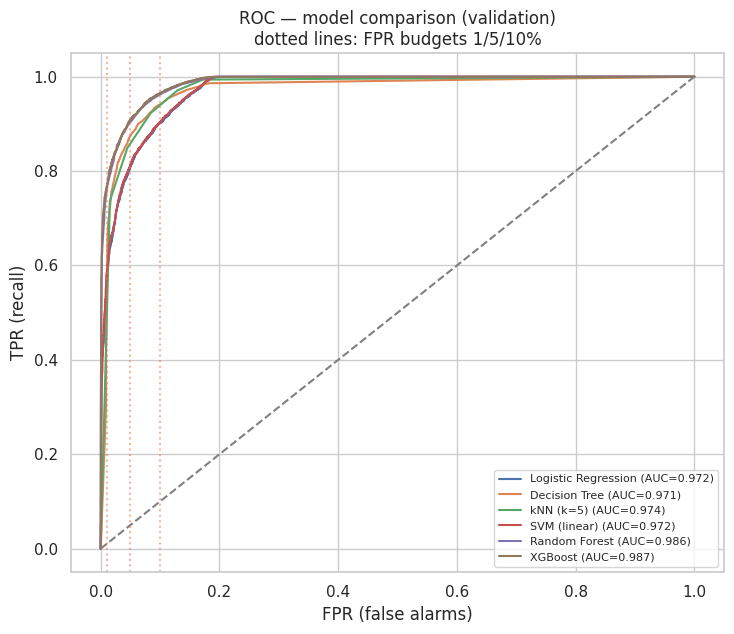

Best candidate on ROC-AUC (validation): XGBoost


In [16]:
plt.figure(figsize=(7.5, 6.5))
for name, (fpr, tpr, _) in rocs.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'ROC_AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
for b in (0.01, 0.05, 0.10):
    plt.axvline(b, ls=":", color="#e76f51", alpha=.5)
plt.xlabel("FPR (false alarms)")
plt.ylabel("TPR (recall)")
plt.title("ROC — model comparison (validation)\ndotted lines: FPR budgets 1/5/10%")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

BEST_MODEL = results.index[0]
print(f"Best candidate on ROC-AUC (validation): {BEST_MODEL}")

## 9. XGBoost hyperparameter tuning

Random search with stratified cross-validation **inside the inner training set**. The test
set is untouched, and so is the validation set: it then serves as a neutral arbiter
between the default and the tuned model.

In [17]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

if RUN_TUNING:
    search_space = {
        "model__n_estimators": randint(200, 600),
        "model__max_depth": randint(3, 11),
        "model__learning_rate": uniform(0.02, 0.28),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.6, 0.4),
        "model__min_child_weight": randint(1, 10),
        "model__reg_lambda": uniform(0.5, 4.5),
    }
    search = RandomizedSearchCV(
        make_pipe(XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=SEED)),
        search_space, n_iter=N_ITER_SEARCH,
        scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
        random_state=SEED, n_jobs=1, verbose=0, refit=True)
    t0 = time.time()
    search.fit(X_tr, y_tr)
    print(f"Search finished in {time.time()-t0:.0f}s over {N_ITER_SEARCH} draws x 3 folds")
    print("Mean cross-validated ROC-AUC:", round(search.best_score_, 4))
    print("Best hyperparameters:")
    for k, v in search.best_params_.items():
        print(f"    {k.replace('model__',''):<20} {round(v, 4) if isinstance(v, float) else v}")
    BEST_XGB_PARAMS = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
else:
    BEST_XGB_PARAMS = {k: v for k, v in XGB_BASE.items()
                       if k not in ("eval_metric", "n_jobs", "random_state")}
    print("Tuning disabled — default hyperparameters kept.")

XGB_FINAL_PARAMS = dict(BEST_XGB_PARAMS, eval_metric="logloss", n_jobs=-1, random_state=SEED)

# arbitration on the validation set: is the tuned model actually better than the default?
xgb_default = make_pipe(XGBClassifier(**XGB_BASE)).fit(X_tr, y_tr)
xgb_tuned = make_pipe(XGBClassifier(**XGB_FINAL_PARAMS)).fit(X_tr, y_tr)

pr_default = xgb_default.predict_proba(X_val)[:, 1]
pr_tuned = xgb_tuned.predict_proba(X_val)[:, 1]

cmp_tbl = pd.DataFrame({
    "default": soc_metrics(y_val, pr_default),
    "tuned": soc_metrics(y_val, pr_tuned),
}).T[["ROC_AUC", "recall", "precision", "F1", "FPR"]].round(4)
print("\nArbitration on the validation set:")
print(cmp_tbl)

USE_TUNED = cmp_tbl.loc["tuned", "ROC_AUC"] >= cmp_tbl.loc["default", "ROC_AUC"]
XGB_CHOSEN = XGB_FINAL_PARAMS if USE_TUNED else dict(XGB_BASE)
print(f"\nModel kept: XGBoost {'tuned' if USE_TUNED else 'default'}")

xgb_sel = make_pipe(XGBClassifier(**XGB_CHOSEN)).fit(X_tr, y_tr)
proba_val = xgb_sel.predict_proba(X_val)[:, 1]

Search finished in 215s over 12 draws x 3 folds
Mean cross-validated ROC-AUC: 0.985
Best hyperparameters:
    colsample_bytree     0.8171
    learning_rate        0.0595
    max_depth            9
    min_child_weight     1
    n_estimators         544
    reg_lambda           4.941
    subsample            0.9089

Arbitration on the validation set:
         ROC_AUC  recall  precision      F1     FPR
default   0.9866  0.9482     0.9194  0.9336  0.0789
tuned     0.9879  0.9494     0.9237  0.9364  0.0745

Model kept: XGBoost tuned


## 10. Decision threshold — on the validation set, two methods

A threshold belongs to the model that produced it. The 0.83 inherited from logistic
regression is definitively abandoned: it is recomputed here from **XGBoost** scores, on the
**validation set**, using the two criteria stated in the analysis.

In [18]:
sweep = pd.DataFrame([
    dict(threshold=round(float(t), 3), **{k: v for k, v in soc_metrics(y_val, proba_val, t).items()})
    for t in np.linspace(0.02, 0.98, 193)
])

# method (a): maximum recall under the constraint FPR <= alpha
methodA = {}
for a in (0.01, 0.05, 0.10):
    ok = sweep[sweep["FPR"] <= a]
    methodA[a] = ok.loc[ok["recall"].idxmax()].to_dict() if len(ok) else sweep.iloc[-1].to_dict()

# method (b): minimum cost C(t) = c_FP*FP + c_FN*FN
methodB = {}
for ratio in (5, 10, 20):
    cost = sweep["FP"] + ratio * sweep["FN"]
    methodB[ratio] = sweep.loc[cost.idxmin()].to_dict()

print("Method (a) — max recall under an FPR constraint:")
for a, r in methodA.items():
    print(f"    FPR<={a:>5.0%} : t={r['threshold']:.3f}  recall={r['recall']:.3f}  "
          f"FPR={r['FPR']:.4f}  precision={r['precision']:.3f}  false alarms={int(r['FP']):,}")

print("\nMethod (b) — minimum cost C(t) = c_FP*FP + c_FN*FN:")
for ratio, r in methodB.items():
    print(f"    c_FN:c_FP={ratio:>2}:1 : t={r['threshold']:.3f}  recall={r['recall']:.3f}  "
          f"FPR={r['FPR']:.4f}  precision={r['precision']:.3f}")

default_op = soc_metrics(y_val, proba_val, 0.50)
soc_op = methodA[FPR_BUDGET]
THRESHOLD = float(soc_op["threshold"])

print(f"\n>>> Threshold kept: {THRESHOLD:.3f}")
print(f"    Policy: maximum recall under FPR <= {FPR_BUDGET:.0%}, computed on the validation")
print(f"    set from XGBoost scores. Provenance recorded in the bundle (§17).")
print(f"\nTrade-off measured on the validation set:")
print(f"    threshold 0.50  : recall={default_op['recall']:.3f}  FPR={default_op['FPR']:.4f}  "
      f"false alarms={default_op['FP']:,}  missed attacks={default_op['FN']:,}")
print(f"    threshold {THRESHOLD:.2f}  : recall={soc_op['recall']:.3f}  FPR={soc_op['FPR']:.4f}  "
      f"false alarms={int(soc_op['FP']):,}  missed attacks={int(soc_op['FN']):,}")
d_fp = (default_op["FP"] - soc_op["FP"]) / max(default_op["FP"], 1)
d_fn = soc_op["FN"] / max(default_op["FN"], 1)
print(f"    -> false alarms -{d_fp:.1%} ; missed attacks x{d_fn:.2f}")

Method (a) — max recall under an FPR constraint:
    FPR<=   1% : t=0.880  recall=0.783  FPR=0.0099  precision=0.987  false alarms=103
    FPR<=   5% : t=0.630  recall=0.912  FPR=0.0495  precision=0.946  false alarms=513
    FPR<=  10% : t=0.390  recall=0.971  FPR=0.0997  precision=0.902  false alarms=1,033

Method (b) — minimum cost C(t) = c_FP*FP + c_FN*FN:
    c_FN:c_FP= 5:1 : t=0.180  recall=0.996  FPR=0.1641  precision=0.852
    c_FN:c_FP=10:1 : t=0.085  recall=1.000  FPR=0.1867  precision=0.836
    c_FN:c_FP=20:1 : t=0.085  recall=1.000  FPR=0.1867  precision=0.836

>>> Threshold kept: 0.630
    Policy: maximum recall under FPR <= 5%, computed on the validation
    set from XGBoost scores. Provenance recorded in the bundle (§17).

Trade-off measured on the validation set:
    threshold 0.50  : recall=0.949  FPR=0.0745  false alarms=772  missed attacks=498
    threshold 0.63  : recall=0.912  FPR=0.0495  false alarms=513  missed attacks=869
    -> false alarms -33.5% ; missed attac

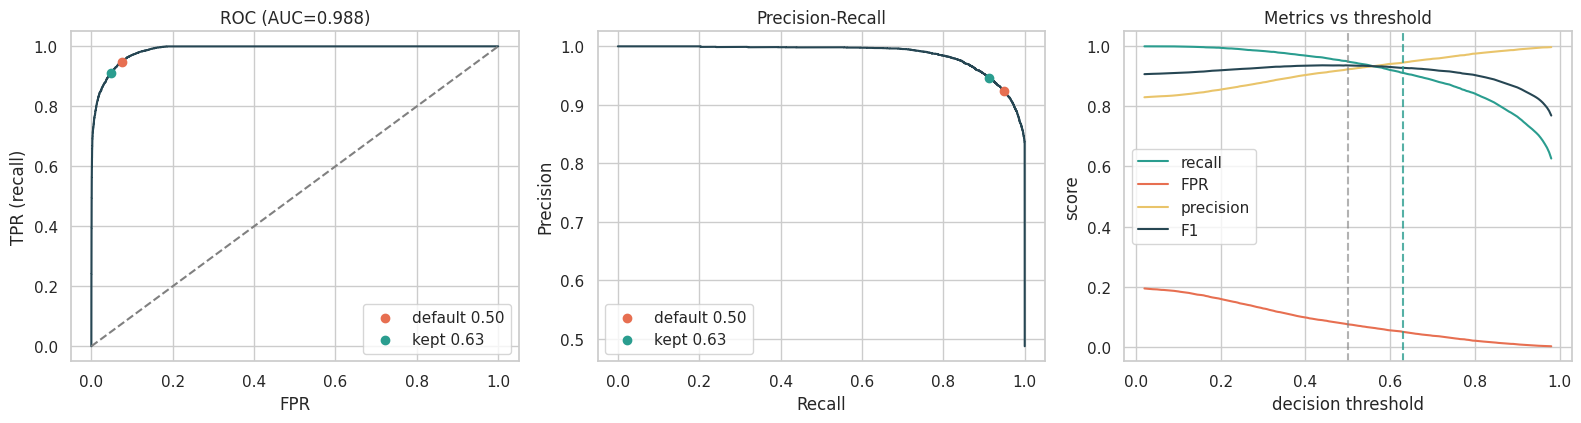

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

fpr_c, tpr_c, _ = roc_curve(y_val, proba_val)
ax[0].plot(fpr_c, tpr_c, color="#264653")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].scatter(default_op["FPR"], default_op["recall"], color="#e76f51", zorder=5, label="default 0.50")
ax[0].scatter(soc_op["FPR"], soc_op["recall"], color="#2a9d8f", zorder=5, label=f"kept {THRESHOLD:.2f}")
ax[0].set(xlabel="FPR", ylabel="TPR (recall)", title=f"ROC (AUC={roc_auc_score(y_val, proba_val):.3f})")
ax[0].legend()

prec_c, rec_c, _ = precision_recall_curve(y_val, proba_val)
ax[1].plot(rec_c, prec_c, color="#264653")
ax[1].scatter(default_op["recall"], default_op["precision"], color="#e76f51", zorder=5, label="default 0.50")
ax[1].scatter(soc_op["recall"], soc_op["precision"], color="#2a9d8f", zorder=5, label=f"kept {THRESHOLD:.2f}")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall")
ax[1].legend()

for c, col in [("recall", "#2a9d8f"), ("FPR", "#e76f51"), ("precision", "#e9c46a"), ("F1", "#264653")]:
    ax[2].plot(sweep["threshold"], sweep[c], label=c, color=col)
ax[2].axvline(0.50, ls="--", color="gray", alpha=.6)
ax[2].axvline(THRESHOLD, ls="--", color="#2a9d8f", alpha=.8)
ax[2].set(xlabel="decision threshold", ylabel="score", title="Metrics vs threshold")
ax[2].legend()
plt.tight_layout()
plt.show()

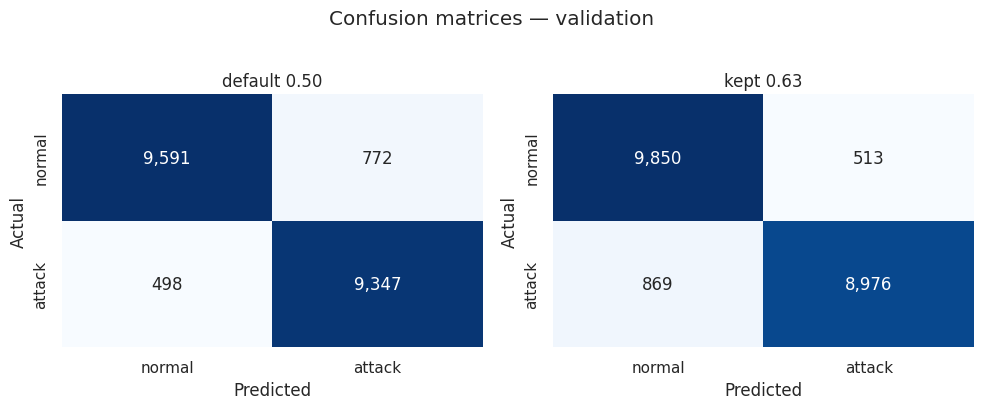

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (t, name) in zip(ax, [(0.50, "default 0.50"), (THRESHOLD, f"kept {THRESHOLD:.2f}")]):
    cm = confusion_matrix(y_val, (proba_val >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", ax=a, cbar=False,
                xticklabels=["normal", "attack"], yticklabels=["normal", "attack"])
    a.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.suptitle("Confusion matrices — validation", y=1.02)
plt.tight_layout()
plt.show()

## 11. Calibration

v3 renamed "probability" to "model score", which was honest but incomplete: we never
checked whether the score *was* calibrated. We measure it here (Brier score + reliability
curve) and test an isotonic recalibration.

Brier score — raw        : 0.04337
Brier score — calibrated : 0.04411  (no improvement)
ROC-AUC — raw 0.9879 | calibrated 0.9875


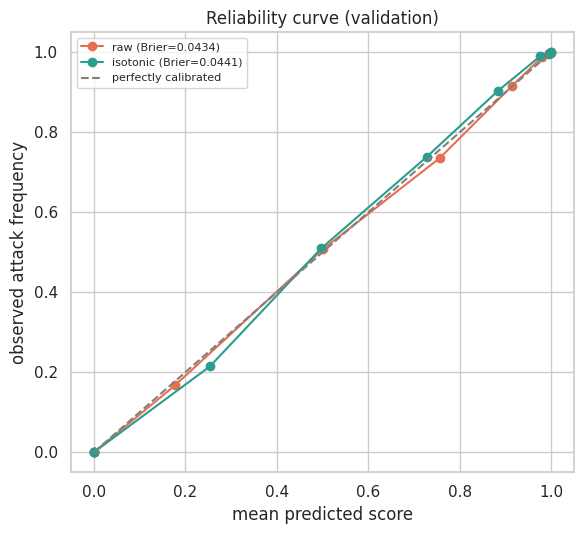


Decision: calibration brings nothing; we keep the term score, not probability.


In [21]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

brier_raw = brier_score_loss(y_val, proba_val)

# recalibration learned on the inner training set only (internal cv), scored on validation
calib = CalibratedClassifierCV(make_pipe(XGBClassifier(**XGB_CHOSEN)), method="isotonic", cv=3)
calib.fit(X_tr, y_tr)
proba_cal = calib.predict_proba(X_val)[:, 1]
brier_cal = brier_score_loss(y_val, proba_cal)

print(f"Brier score — raw        : {brier_raw:.5f}")
print(f"Brier score — calibrated : {brier_cal:.5f}  ({'improvement' if brier_cal < brier_raw else 'no improvement'})")
print(f"ROC-AUC — raw {roc_auc_score(y_val, proba_val):.4f} | calibrated {roc_auc_score(y_val, proba_cal):.4f}")

plt.figure(figsize=(6, 5.5))
for pr, lab, col in [(proba_val, f"raw (Brier={brier_raw:.4f})", "#e76f51"),
                     (proba_cal, f"isotonic (Brier={brier_cal:.4f})", "#2a9d8f")]:
    fr_pos, mean_pred = calibration_curve(y_val, pr, n_bins=15, strategy="quantile")
    plt.plot(mean_pred, fr_pos, "o-", label=lab, color=col)
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfectly calibrated")
plt.xlabel("mean predicted score")
plt.ylabel("observed attack frequency")
plt.title("Reliability curve (validation)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

CALIBRATED = brier_cal < brier_raw
print(f"\nDecision: {'the score will be calibrated before display — it may then be called a probability.' if CALIBRATED else 'calibration brings nothing; we keep the term score, not probability.'}")

## 12. Explainability — SHAP and permutation importance

SHAP tells what the model uses. Permutation importance tells what it *needs*. Together
they are more solid than SHAP alone.

In [22]:
import shap
import scipy.sparse as sp

prep_fitted = xgb_sel.named_steps["prep"]
xgb_fitted = xgb_sel.named_steps["model"]
feat_names = [f.split("__")[-1] for f in prep_fitted.get_feature_names_out()]

Xva_t = prep_fitted.transform(X_val)
Xva_arr = Xva_t.toarray() if sp.issparse(Xva_t) else np.asarray(Xva_t)

rng = np.random.RandomState(SEED)
n_shap = min(3000, len(Xva_arr))
idx = rng.choice(len(Xva_arr), n_shap, replace=False)

explainer = shap.TreeExplainer(xgb_fitted)
shap_values = explainer.shap_values(Xva_arr[idx])
print("SHAP computed:", np.shape(shap_values))
print("\nNote for the report: for XGBoost in binary classification, SHAP values are expressed")
print("in log-odds, NOT in probability percentage points. They measure a contribution to the")
print("model score, never a causal relationship.")

SHAP computed: (3000, 65)

Note for the report: for XGBoost in binary classification, SHAP values are expressed
in log-odds, NOT in probability percentage points. They measure a contribution to the
model score, never a causal relationship.


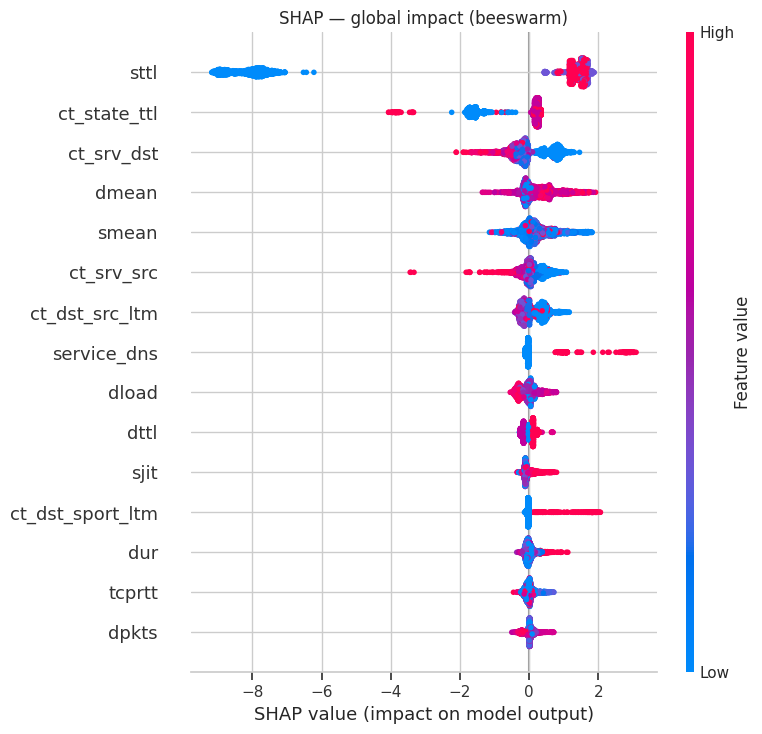

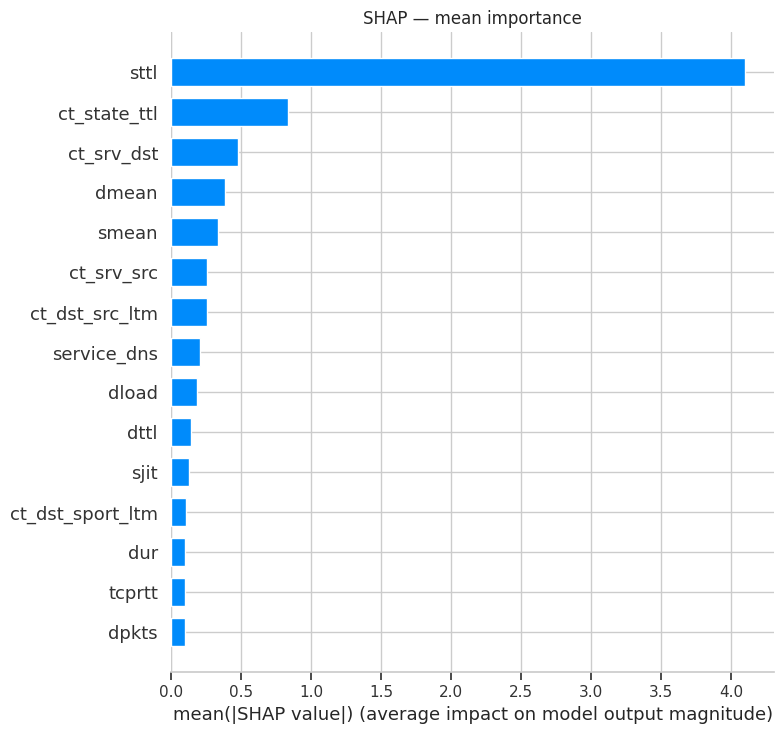

Top 10 SHAP:
sttl              4.1032
ct_state_ttl      0.8329
ct_srv_dst        0.4766
dmean             0.3871
smean             0.3367
ct_srv_src        0.2565
ct_dst_src_ltm    0.2563
service_dns       0.2064
dload             0.1851
dttl              0.1393
dtype: float32


In [23]:
shap.summary_plot(shap_values, Xva_arr[idx], feature_names=feat_names, max_display=15, show=False)
plt.title("SHAP — global impact (beeswarm)")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values, Xva_arr[idx], feature_names=feat_names,
                  plot_type="bar", max_display=15, show=False)
plt.title("SHAP — mean importance")
plt.tight_layout()
plt.show()

shap_rank = pd.Series(np.abs(shap_values).mean(0), index=feat_names).sort_values(ascending=False)
print("Top 10 SHAP:")
print(shap_rank.head(10).round(4))

Permutation importance (ROC-AUC drop when the variable is shuffled):
                importance      std
sttl               0.25886  0.00450
dmean              0.00905  0.00072
smean              0.00834  0.00063
service            0.00699  0.00092
ct_srv_dst         0.00593  0.00036
ct_dst_src_ltm     0.00443  0.00044
ct_state_ttl       0.00393  0.00035
ct_srv_src         0.00314  0.00013
synack             0.00164  0.00020
ct_dst_ltm         0.00145  0.00019
ct_src_ltm         0.00119  0.00022
dload              0.00116  0.00006


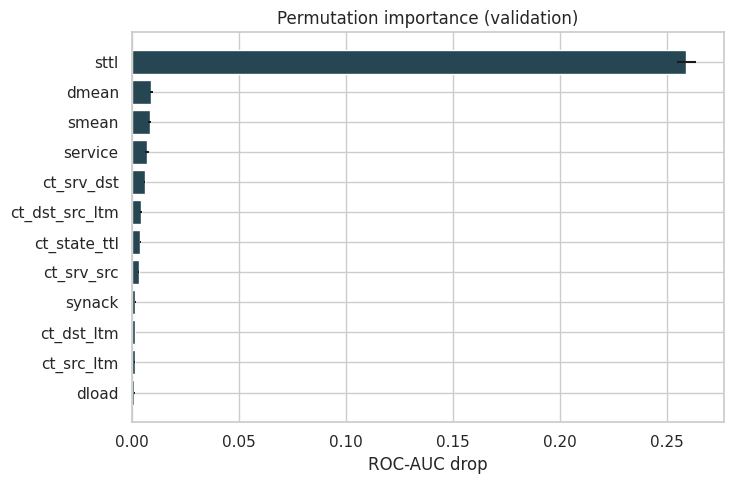


SHAP and permutation importance do not necessarily rank in the same order:
SHAP measures actual usage, permutation measures dependence. A marked gap signals a
redundant variable — the model uses it, but could do without it.


In [24]:
from sklearn.inspection import permutation_importance

n_perm = min(5000, len(X_val))
perm_idx = rng.choice(len(X_val), n_perm, replace=False)
perm = permutation_importance(
    xgb_sel, X_val.iloc[perm_idx], y_val[perm_idx],
    n_repeats=5, random_state=SEED, scoring="roc_auc", n_jobs=1)

perm_tbl = pd.DataFrame({
    "importance": perm.importances_mean,
    "std": perm.importances_std,
}, index=X_val.columns).sort_values("importance", ascending=False)

print("Permutation importance (ROC-AUC drop when the variable is shuffled):")
print(perm_tbl.head(12).round(5))

plt.figure(figsize=(7.5, 5))
top = perm_tbl.head(12).iloc[::-1]
plt.barh(top.index, top["importance"], xerr=top["std"], color="#264653")
plt.xlabel("ROC-AUC drop")
plt.title("Permutation importance (validation)")
plt.tight_layout()
plt.show()

print("\nSHAP and permutation importance do not necessarily rank in the same order:")
print("SHAP measures actual usage, permutation measures dependence. A marked gap signals a")
print("redundant variable — the model uses it, but could do without it.")

## 13. Ablation — is `sttl` a dataset shortcut?

This is the critical question raised by the analysis. If removing `sttl` and
`ct_state_ttl` collapses performance, then the model has not learned attack behaviour: it
has learned an artefact of how UNSW-NB15 was built, and it will not generalise to real
traffic.

  full model                     ROC-AUC=0.9879
  without sttl                   ROC-AUC=0.9880
  without sttl + ct_state_ttl    ROC-AUC=0.9877
  without all ct_*               ROC-AUC=0.9813

=== Ablation study (validation) ===
                             n_features  ROC_AUC  recall@FPR<=5%  recall@threshold  FPR@threshold
variant                                                                                          
full model                           36   0.9879          0.9124            0.9117         0.0495
without sttl                         35   0.9880          0.9171            0.9142         0.0484
without sttl + ct_state_ttl          34   0.9877          0.9147            0.9136         0.0493
without all ct_*                     27   0.9813          0.8615            0.8952         0.0672

Removing `sttl` costs -0.0001 ROC-AUC (-0.0% relative).
Limited drop: the model does not rest on `sttl` alone. Performance survives its
removal, which strengthens the credibility of 

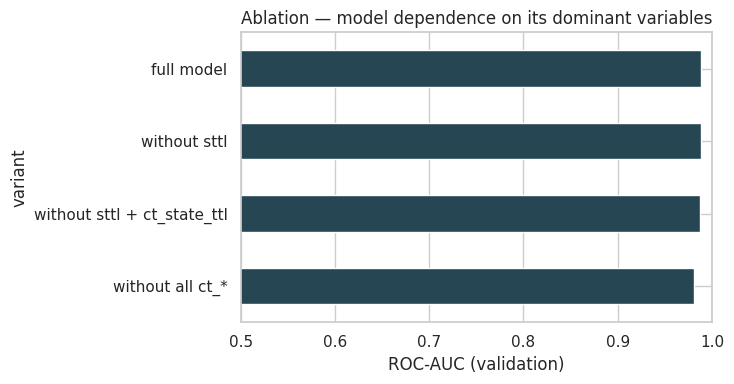

In [25]:
ABLATIONS = {
    "full model": [],
    "without sttl": ["sttl"],
    "without sttl + ct_state_ttl": ["sttl", "ct_state_ttl"],
    "without all ct_*": [c for c in num_cols if c.startswith("ct_")],
}

abl_rows = []
for name, drop in ABLATIONS.items():
    drop = [c for c in drop if c in X_tr.columns]
    keep_num = [c for c in num_cols if c not in drop]
    keep_cat = [c for c in cat_cols if c not in drop]
    cols = keep_num + keep_cat
    p = make_pipe(XGBClassifier(**XGB_CHOSEN), numeric=keep_num, categorical=keep_cat)
    p.fit(X_tr[cols], y_tr)
    pr = p.predict_proba(X_val[cols])[:, 1]
    met = soc_metrics(y_val, pr, THRESHOLD)
    r_at, _ = recall_at_fpr(y_val, pr, FPR_BUDGET)
    abl_rows.append({"variant": name, "n_features": len(cols), "ROC_AUC": met["ROC_AUC"],
                     f"recall@FPR<={int(FPR_BUDGET*100)}%": r_at,
                     "recall@threshold": met["recall"], "FPR@threshold": met["FPR"]})
    print(f"  {name:<30} ROC-AUC={met['ROC_AUC']:.4f}")

abl_tbl = pd.DataFrame(abl_rows).set_index("variant").round(4)
print("\n=== Ablation study (validation) ===")
print(abl_tbl)

full_auc = abl_tbl.loc["full model", "ROC_AUC"]
drop_sttl = full_auc - abl_tbl.loc["without sttl", "ROC_AUC"]
print(f"\nRemoving `sttl` costs {drop_sttl:.4f} ROC-AUC ({drop_sttl/full_auc:.1%} relative).")
if drop_sttl > 0.05:
    print("Large drop: the model depends heavily on `sttl`. To be reported as a major")
    print("limitation — the announced performance is partly carried by a dataset construction")
    print("artefact rather than by a generalisable attack signal.")
else:
    print("Limited drop: the model does not rest on `sttl` alone. Performance survives its")
    print("removal, which strengthens the credibility of the results.")

plt.figure(figsize=(7.5, 4))
abl_tbl["ROC_AUC"].iloc[::-1].plot(kind="barh", color="#264653")
plt.xlabel("ROC-AUC (validation)")
plt.title("Ablation — model dependence on its dominant variables")
plt.xlim(min(0.5, abl_tbl["ROC_AUC"].min() - 0.05), 1.0)
plt.tight_layout()
plt.show()

## 14. Detailed error analysis

"Turning a classification result into a cybersecurity analysis." We work on the
**validation set**: the test set stays sealed. Four tables, the ones the analysis asked for.

=== 14.1 — Detection by attack category (validation, chosen threshold) ===
                total  detected  missed  recall  mean_score
attack_cat                                                 
Analysis          116        72      44   0.621       0.690
Fuzzers          2981      2228     753   0.747       0.760
Shellcode         215       210       5   0.977       0.945
DoS               599       588      11   0.982       0.970
Exploits         3676      3625      51   0.986       0.980
Generic           798       794       4   0.995       0.993
Reconnaissance   1314      1313       1   0.999       0.990
Backdoor          120       120       0   1.000       0.988
Worms              26        26       0   1.000       0.992

Least detected category: Analysis (recall=62.1% over 116 flows)
This line, not the overall accuracy, is what a SOC analyst cares about.


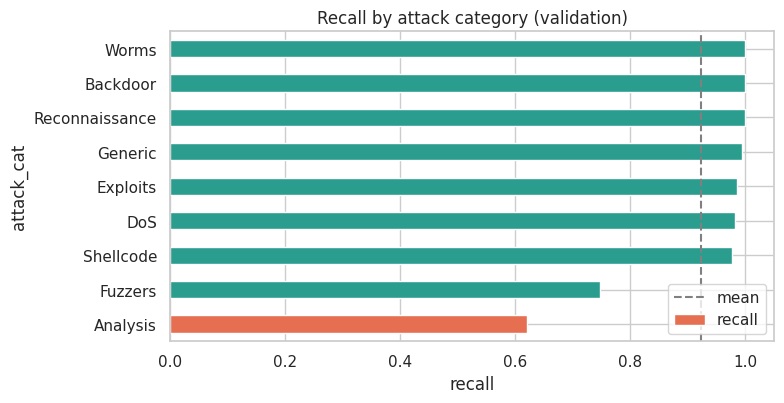

In [26]:
pred_val = (proba_val >= THRESHOLD).astype(int)
err_df = X_val.copy()
err_df["y_true"] = y_val
err_df["y_pred"] = pred_val
err_df["score"] = proba_val
err_df["attack_cat"] = cat_val

# --- 14.1 False negatives by attack category
fn_tbl = (err_df[err_df["y_true"] == 1]
          .groupby("attack_cat")
          .agg(total=("y_true", "size"),
               detected=("y_pred", "sum"),
               mean_score=("score", "mean"))
          .assign(missed=lambda d: d["total"] - d["detected"],
                  recall=lambda d: d["detected"] / d["total"])
          .sort_values("recall"))
print("=== 14.1 — Detection by attack category (validation, chosen threshold) ===")
print(fn_tbl[["total", "detected", "missed", "recall", "mean_score"]].round(3))
worst = fn_tbl.index[0]
print(f"\nLeast detected category: {worst} "
      f"(recall={fn_tbl.loc[worst, 'recall']:.1%} over {int(fn_tbl.loc[worst, 'total'])} flows)")
print("This line, not the overall accuracy, is what a SOC analyst cares about.")

plt.figure(figsize=(8, 4.2))
fn_tbl["recall"].plot(kind="barh", color=["#e76f51" if v < 0.7 else "#2a9d8f" for v in fn_tbl["recall"]])
plt.axvline(fn_tbl["recall"].mean(), ls="--", color="gray", label="mean")
plt.xlabel("recall")
plt.title("Recall by attack category (validation)")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# --- 14.2 False positives by protocol and by service
fp_mask = (err_df["y_true"] == 0) & (err_df["y_pred"] == 1)
print("=== 14.2 — Where false alarms come from ===")
for col in [c for c in ("proto", "service", "state") if c in err_df.columns]:
    tbl = (err_df[err_df["y_true"] == 0]
           .groupby(col)
           .agg(normal_flows=("y_true", "size"), false_alarms=("y_pred", "sum"))
           .assign(rate=lambda d: d["false_alarms"] / d["normal_flows"])
           .sort_values("false_alarms", ascending=False))
    print(f"\nBy {col}:")
    print(tbl.head(8).round(3))

print("\nSOC reading: a protocol or service concentrating false alarms is a direct candidate")
print("for a differentiated threshold, or for a filtering rule upstream of the model.")

=== 14.2 — Where false alarms come from ===

By proto:
       normal_flows  false_alarms   rate
proto                                   
tcp            7716           398  0.052
udp            2508           114  0.045
other             1             1  1.000
igmp              2             0  0.000
icmp              3             0  0.000
arp             122             0  0.000
ospf             11             0  0.000

By service:
          normal_flows  false_alarms   rate
service                                    
none              6616           406  0.061
http              1037            67  0.065
ftp                229            32  0.140
smtp               315             3  0.010
radius               2             2  1.000
pop3                 2             2  1.000
dns               1418             1  0.001
ftp-data           502             0  0.000

By state:
       normal_flows  false_alarms   rate
state                                   
FIN            7371           

In [28]:
# --- 14.3 Errors by duration / volume bucket
print("=== 14.3 — Errors by flow size ===")
for col in [c for c in ("dur", "sbytes", "spkts", "smean") if c in err_df.columns]:
    try:
        bins = pd.qcut(err_df[col], 5, duplicates="drop")
    except ValueError:
        continue
    tbl = (err_df.groupby(bins, observed=True)
           .apply(lambda g: pd.Series({
               "n": len(g),
               "FP": int(((g.y_true == 0) & (g.y_pred == 1)).sum()),
               "FN": int(((g.y_true == 1) & (g.y_pred == 0)).sum()),
           }), include_groups=False))
    tbl["error_rate"] = (tbl["FP"] + tbl["FN"]) / tbl["n"]
    print(f"\nBy quintile of {col}:")
    print(tbl.round(3))
    break

=== 14.3 — Errors by flow size ===

By quintile of dur:
                      n   FP   FN  error_rate
dur                                          
(-0.001, 0.00152]  4042  112  155       0.066
(0.00152, 0.119]   4041    3    0       0.001
(0.119, 0.625]     4042   98  252       0.087
(0.625, 1.135]     4041  123  346       0.116
(1.135, 60.0]      4042  177  116       0.072


In [29]:
# --- 14.4 Observations near the threshold: the SOC grey zone
band = 0.05
near = err_df[(err_df["score"] >= THRESHOLD - band) & (err_df["score"] <= THRESHOLD + band)]
print(f"=== 14.4 — Grey zone: scores in [{THRESHOLD-band:.2f}, {THRESHOLD+band:.2f}] ===")
print(f"{len(near):,} flows ({len(near)/len(err_df):.2%} of the validation set)")
if len(near):
    print(f"  of which truly attacks: {int(near['y_true'].sum()):,} ({near['y_true'].mean():.1%})")
    print("\nComposition by category:")
    print(near["attack_cat"].value_counts().head(8))
print("\nThese flows are the ones an analyst should review first: the model is least sure of")
print("itself there. A 'to review' queue built on this band is a concrete operational lead")
print("for the prototype.")

=== 14.4 — Grey zone: scores in [0.58, 0.68] ===
534 flows (2.64% of the validation set)
  of which truly attacks: 336 (62.9%)

Composition by category:
attack_cat
Fuzzers           298
Normal            198
Exploits           18
DoS                 7
Analysis            6
Shellcode           3
Reconnaissance      2
Generic             2
Name: count, dtype: int64

These flows are the ones an analyst should review first: the model is least sure of
itself there. A 'to review' queue built on this band is a concrete operational lead
for the prototype.


## 15. Final evaluation — sealed test set, single evaluation

The **only** cell that touches the official test partition. The selected configuration is refit on
the full official training partition (inner train + validation), then evaluated **once** at the
threshold chosen in §10. 95% confidence intervals by bootstrap.

**Methodological note.** The threshold 0.630 was selected on the scores of the model fitted on the
inner training subset. The model evaluated here is a new estimator refit on train + validation.
A threshold belongs to the score distribution of the estimator actually trained, so the
validation → test comparison mixes a possible dataset shift with a possible score shift caused by
the refit. §15.1 examines the shift on normal flows only. The threshold is not recalibrated on test.

In [30]:
final = make_pipe(XGBClassifier(**XGB_CHOSEN))
final.fit(X_train_full, y_train_full)
test_proba = final.predict_proba(X_test)[:, 1]

pt = soc_metrics(y_test, test_proba, THRESHOLD)
auc_test = roc_auc_score(y_test, test_proba)

rng_b = np.random.default_rng(SEED)
n = len(y_test)
B = {k: [] for k in ("recall", "FPR", "precision", "F1", "auc")}
for _ in range(1000):
    s = rng_b.integers(0, n, n)
    if len(np.unique(y_test[s])) < 2:
        continue
    d = soc_metrics(y_test[s], test_proba[s], THRESHOLD)
    for k in ("recall", "FPR", "precision", "F1"):
        B[k].append(d[k])
    B["auc"].append(roc_auc_score(y_test[s], test_proba[s]))
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in B.items() if v}

print(f"=== FINAL PERFORMANCE — sealed test, single evaluation, threshold {THRESHOLD:.3f} ===\n")
print(f"{'ROC-AUC':<12} {auc_test:.4f}   95% CI [{ci['auc'][0]:.4f}, {ci['auc'][1]:.4f}]")
for k, lbl in [("recall", "recall"), ("FPR", "FPR"), ("precision", "precision"), ("F1", "F1")]:
    print(f"{lbl:<12} {pt[k]:.4f}   95% CI [{ci[k][0]:.4f}, {ci[k][1]:.4f}]")
print(f"\nMatrix: TP={pt['TP']:,}  FP={pt['FP']:,}  FN={pt['FN']:,}  TN={pt['TN']:,}")
print(f"SOC load: {pt['TP']+pt['FP']:,} alerts, of which {pt['FP']:,} false "
      f"({pt['FP']/max(pt['TP']+pt['FP'],1):.1%})")

print("\nValidation -> test comparison at the selected operating point:")
print(f"    recall  {soc_op['recall']:.4f} -> {pt['recall']:.4f}")
print(f"    FPR     {soc_op['FPR']:.4f} -> {pt['FPR']:.4f}")
print("A substantial validation-to-test degradation is observed at the selected operating point.")
print("It is consistent with distributional differences between the official partitions (§2.6, §15.1),")
print("although part of it may result from refitting the final estimator on the full training set.")
print("Dataset shift is therefore a plausible contributing factor, not a uniquely established cause.")
print("The threshold is NOT recalibrated on the test set: this result is reported as final.")

# --- final error breakdown by category (descriptive, not a choice)
test_err = pd.DataFrame({"y_true": y_test, "score": test_proba, "attack_cat": cat_test})
test_err["y_pred"] = (test_proba >= THRESHOLD).astype(int)
fn_test = (test_err[test_err["y_true"] == 1].groupby("attack_cat")
           .agg(total=("y_true", "size"), detected=("y_pred", "sum"))
           .assign(missed=lambda d: d["total"] - d["detected"],
                   recall=lambda d: d["detected"] / d["total"])
           .sort_values("recall"))
print("\nDetection by category on the sealed test set:")
print(fn_test.round(3))

# --- effect of the train/test overlap measured in §2.4
if n_overlap:
    seen = overlap_mask[:len(y_test)] if len(overlap_mask) == len(y_test) else None
    if seen is not None and seen.any() and (~seen).any():
        m_seen = soc_metrics(y_test[seen], test_proba[seen], THRESHOLD)
        m_new = soc_metrics(y_test[~seen], test_proba[~seen], THRESHOLD)
        print(f"\nEffect of the train/test overlap ({n_overlap:,} already-seen flows):")
        print(f"    already seen flows : recall={m_seen['recall']:.4f}  FPR={m_seen['FPR']:.4f}")
        print(f"    never seen flows   : recall={m_new['recall']:.4f}  FPR={m_new['FPR']:.4f}")
        print("    The degradation is present in both groups, so train/test overlap is not the main")
        print("    explanation. Ruling out overlap does not by itself establish dataset shift.")

=== FINAL PERFORMANCE — sealed test, single evaluation, threshold 0.630 ===

ROC-AUC      0.9840   95% CI [0.9834, 0.9846]
recall       0.9729   95% CI [0.9713, 0.9745]
FPR          0.1961   95% CI [0.1919, 0.1999]
precision    0.8588   95% CI [0.8557, 0.8618]
F1           0.9123   95% CI [0.9105, 0.9142]

Matrix: TP=44,105  FP=7,254  FN=1,227  TN=29,746
SOC load: 51,359 alerts, of which 7,254 false (14.1%)

Validation -> test comparison at the selected operating point:
    recall  0.9117 -> 0.9729
    FPR     0.0495 -> 0.1961
A substantial validation-to-test degradation is observed at the selected operating point.
It is consistent with distributional differences between the official partitions (§2.6, §15.1),
although part of it may result from refitting the final estimator on the full training set.
Dataset shift is therefore a plausible contributing factor, not a uniquely established cause.
The threshold is NOT recalibrated on the test set: this result is reported as final.

Detection

### 15.1. Post-hoc diagnostic — is the shift present in normal traffic?

FPR = FP / (FP + TN) depends only on normal flows. The relevant comparison is therefore
P(X | Y = normal, validation) versus P(X | Y = normal, test), not the global train/test comparison
of §2.6. This cell is descriptive only: it changes no model, no threshold and no earlier decision.

In [31]:
from scipy.stats import ks_2samp

val_norm = val_df[val_df[LABEL_COL] == 0]
test_norm = test_c[test_c[LABEL_COL] == 0]
print(f"Normal flows — validation: {len(val_norm):,}   test: {len(test_norm):,}")

rows_sn = []
for c in num_cols:
    a, b = val_norm[c].to_numpy(), test_norm[c].to_numpy()
    med_a, med_b = np.median(a), np.median(b)
    rows_sn.append({
        "feature": c,
        "val_median": med_a,
        "test_median": med_b,
        "rel_median_gap": abs(med_b - med_a) / abs(med_a) if med_a != 0 else np.nan,
        "KS": ks_2samp(a, b).statistic,
    })
shift_norm = pd.DataFrame(rows_sn).set_index("feature").sort_values("KS", ascending=False)
print("\nTop 10 shifted features among NORMAL flows (validation vs test), ranked by KS statistic:")
print(shift_norm.head(10).round(3))

print("\nConnection state among NORMAL flows (% of normal flows):")
state_norm = pd.DataFrame({
    "validation_%": val_norm["state"].value_counts(normalize=True) * 100,
    "test_%": test_norm["state"].value_counts(normalize=True) * 100,
}).fillna(0).round(2).sort_values("test_%", ascending=False)
print(state_norm)

nm = (y_test == 0)
fp_state_test = (pd.DataFrame({"state": test_c["state"].to_numpy()[nm],
                               "false_alarm": (test_proba[nm] >= THRESHOLD).astype(int)})
                 .groupby("state")
                 .agg(normal_flows=("false_alarm", "size"), false_alarms=("false_alarm", "sum"))
                 .assign(rate=lambda d: d.false_alarms / d.normal_flows,
                         share_of_all_FP=lambda d: d.false_alarms / d.false_alarms.sum())
                 .sort_values("false_alarms", ascending=False))
print("\nTest false alarms by connection state (normal flows only):")
print(fp_state_test.round(3))

print("\nReading: large gaps among normal flows support dataset shift as a plausible contributor")
print("to the FPR gap. Small gaps would shift weight towards the refit explanation. In both cases,")
print("the mémoire presents shift as plausible, not as a demonstrated sole cause.")

Normal flows — validation: 10,363   test: 37,000

Top 10 shifted features among NORMAL flows (validation vs test), ranked by KS statistic:
              val_median  test_median  rel_median_gap     KS
feature                                                     
ct_state_ttl       0.000        1.000             NaN  0.309
sttl              31.000       62.000           1.000  0.292
dload         509547.312     7679.022           0.985  0.286
dmean             91.000       76.000           0.165  0.255
ackdat             0.000        0.000           0.159  0.227
dttl              29.000       29.000           0.000  0.203
tcprtt             0.001        0.001           0.078  0.199
synack             0.001        0.001           0.057  0.199
dpkts             14.000        8.000           0.429  0.194
rate            1486.200      118.626           0.920  0.175

Connection state among NORMAL flows (% of normal flows):
       validation_%  test_%
state                      
FIN           7

## 16. Multiclass classification — hierarchical architecture

Multiclass mode did not work: flipping `TARGET` broke every downstream cell, all written
for the binary case. Rather than a fragile switch, we implement the **hierarchical**
architecture recommended by the analysis:

1. **stage 1** — the already validated binary model decides *normal / attack*;
2. **stage 2** — a second model, trained on attacks only, qualifies the **category**.

This separation matches the real work of a SOC: detect, then qualify. It also isolates two
distinct difficulties — and this is where imbalance becomes truly critical, some families
being very rare.

Attack category distribution (inner training set):
                    n    pct
Analysis          426   1.08
Backdoor          393   1.00
DoS              2405   6.11
Exploits        15045  38.20
Fuzzers         11908  30.24
Generic          3126   7.94
Reconnaissance   5108  12.97
Shellcode         874   2.22
Worms              95   0.24

Most frequent / rarest class ratio: 158:1  -> severe imbalance, unlike the binary case.

=== Stage 2 — category qualification (validation, attacks only) ===
                macro_F1  weighted_F1  balanced_acc  accuracy
unweighted        0.7301       0.8699        0.6952    0.8750
class-weighted    0.7209       0.8566        0.7972    0.8501

Macro-F1 and balanced accuracy weight every class equally: they are what reveals
the failure on rare classes, which accuracy hides completely.
    balanced accuracy +0.1020   |   macro-F1 (control) -0.0092
Strategy kept for stage 2: class-weighted (selected on balanced accuracy — stage 2 exists to qualify rare at

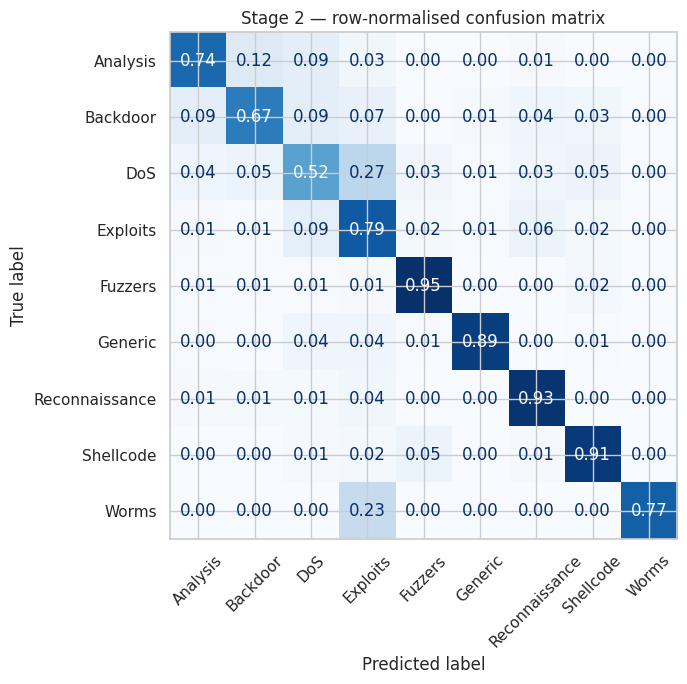


=== Full hierarchical chain (stage 1 + stage 2), validation ===
macro-F1         : 0.6923
weighted-F1      : 0.8618
balanced accuracy: 0.7469

An attack missed at stage 1 is lost for good: it will never be qualified. Stage 1
recall therefore caps the whole chain.


In [32]:
if RUN_MULTICLASS:
    from sklearn.preprocessing import LabelEncoder
    from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay

    # --- stage 2: trained ONLY on the attacks of the inner training set
    atk_tr = tr_df[tr_df[LABEL_COL] == 1]
    atk_val = val_df[val_df[LABEL_COL] == 1]

    Xc_tr = atk_tr.drop(columns=DROP_TARGETS)
    Xc_val = atk_val.drop(columns=DROP_TARGETS)

    le = LabelEncoder().fit(atk_tr[CAT_COL])
    yc_tr = le.transform(atk_tr[CAT_COL])
    keep = np.isin(atk_val[CAT_COL], le.classes_)
    Xc_val, yc_val = Xc_val[keep], le.transform(atk_val[CAT_COL][keep])

    dist = pd.Series(yc_tr).value_counts().sort_index()
    dist.index = le.classes_[dist.index]
    print("Attack category distribution (inner training set):")
    print(dist.to_frame("n").assign(pct=lambda d: (d.n / d.n.sum() * 100).round(2)))
    print(f"\nMost frequent / rarest class ratio: "
          f"{dist.max() / max(dist.min(), 1):.0f}:1  -> severe imbalance, unlike the binary case.")

    # class weights: THIS is where rebalancing makes sense
    counts = np.bincount(yc_tr)
    w = len(yc_tr) / (len(counts) * np.maximum(counts, 1))
    sample_w = w[yc_tr]

    multi_results = {}
    for tag, sw in [("unweighted", None), ("class-weighted", sample_w)]:
        mc = make_pipe(XGBClassifier(
            objective="multi:softprob", num_class=len(le.classes_),
            n_estimators=300, max_depth=6, learning_rate=0.1,
            eval_metric="mlogloss", n_jobs=-1, random_state=SEED))
        mc.fit(Xc_tr, yc_tr, **({"model__sample_weight": sw} if sw is not None else {}))
        pc = mc.predict(Xc_val)
        multi_results[tag] = {
            "macro_F1": f1_score(yc_val, pc, average="macro", zero_division=0),
            "weighted_F1": f1_score(yc_val, pc, average="weighted", zero_division=0),
            "balanced_acc": balanced_accuracy_score(yc_val, pc),
            "accuracy": accuracy_score(yc_val, pc),
            "_model": mc, "_pred": pc,
        }

    mtbl = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if not kk.startswith("_")}
                         for k, v in multi_results.items()}).T.round(4)
    print("\n=== Stage 2 — category qualification (validation, attacks only) ===")
    print(mtbl)
    print("\nMacro-F1 and balanced accuracy weight every class equally: they are what reveals")
    print("the failure on rare classes, which accuracy hides completely.")

    # Selection criterion: balanced accuracy (mean per-class recall), because stage 2 exists to keep
    # every attack family visible, including rare ones. Macro-F1 is kept as a CONTROL metric, because
    # balanced accuracy does not account for the precision lost through class weighting.
    best_mc = max(multi_results, key=lambda k: multi_results[k]["balanced_acc"])
    other_mc = [k for k in multi_results if k != best_mc][0]
    d_ba = multi_results[best_mc]["balanced_acc"] - multi_results[other_mc]["balanced_acc"]
    d_f1 = multi_results[best_mc]["macro_F1"] - multi_results[other_mc]["macro_F1"]
    print(f"    balanced accuracy {d_ba:+.4f}   |   macro-F1 (control) {d_f1:+.4f}")
    print(f"Strategy kept for stage 2: {best_mc} (selected on balanced accuracy — stage 2 exists to qualify rare attack families, so a criterion that weights every class equally is the right arbiter)")
    pred_c = multi_results[best_mc]["_pred"]

    print("\nRecall by attack category:")
    print(pd.DataFrame(classification_report(
        yc_val, pred_c, target_names=le.classes_, output_dict=True, zero_division=0)
    ).T[["precision", "recall", "f1-score", "support"]].round(3))

    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        yc_val, pred_c, display_labels=le.classes_, normalize="true",
        xticks_rotation=45, cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title("Stage 2 — row-normalised confusion matrix")
    plt.tight_layout()
    plt.show()

    # --- full chain: stage 1 then stage 2, evaluated end to end on the validation set
    stage1 = (proba_val >= THRESHOLD).astype(int)
    full_pred = np.array(["Normal"] * len(X_val), dtype=object)
    flagged = np.where(stage1 == 1)[0]
    if len(flagged):
        full_pred[flagged] = le.inverse_transform(
            multi_results[best_mc]["_model"].predict(X_val.iloc[flagged]))

    truth = np.where(y_val == 1, cat_val, "Normal")
    print("\n=== Full hierarchical chain (stage 1 + stage 2), validation ===")
    print(f"macro-F1         : {f1_score(truth, full_pred, average='macro', zero_division=0):.4f}")
    print(f"weighted-F1      : {f1_score(truth, full_pred, average='weighted', zero_division=0):.4f}")
    print(f"balanced accuracy: {balanced_accuracy_score(truth, full_pred):.4f}")
    print("\nAn attack missed at stage 1 is lost for good: it will never be qualified. Stage 1")
    print("recall therefore caps the whole chain.")
else:
    print("Multiclass disabled (RUN_MULTICLASS = False).")

## 17. Model saving — with threshold provenance

In [33]:
import joblib
from datetime import datetime

bundle = {
    "pipeline": final,
    "threshold": THRESHOLD,
    "threshold_provenance": {
        "model": "XGBoost",
        "computed_on": "validation split carved out of the official training set",
        "method": f"maximum recall under the constraint FPR <= {FPR_BUDGET:.0%}",
        "note": "replaces the 0.83 inherited from logistic regression",
        "alternatives": {f"FPR<={a:.0%}": round(r["threshold"], 3) for a, r in methodA.items()},
    },
    "hyperparams": XGB_CHOSEN,
    "tuned": bool(USE_TUNED) if RUN_TUNING else False,
    "prep_params": params,
    "cat": cat_cols,
    "num": num_cols,
    "deduplicated": DROP_DUPLICATES,
    "calibrated": bool(CALIBRATED),
    "test_metrics": {k: float(pt[k]) for k in ("recall", "FPR", "precision", "F1")},
    "test_auc": float(auc_test),
    "test_ci95": {k: [float(v[0]), float(v[1])] for k, v in ci.items()},
    "ablation": abl_tbl.to_dict(),
    "version": "v4",
    "created": datetime.now().isoformat(timespec="seconds"),
}
joblib.dump(bundle, f"{DATA}/ids_xgb_bundle.joblib")
print(f"Bundle saved — threshold {THRESHOLD:.3f}, version v4, provenance recorded.")

Bundle saved — threshold 0.630, version v4, provenance recorded.


## 18. Analyst dashboard

Fixes carried over from v3 (`risk_level` reordered, "model score") and completed: every
alert now carries **model, version, threshold, score, decision, triggering variables with
their raw values, flow id and timestamp** — the exact list the analysis asked for. **Batch
prediction** on CSV is added.

In [34]:
DASHBOARD = True   # False for a non-interactive run (verification, CI)

if DASHBOARD:
    try:
        import ipywidgets as widgets
        from IPython.display import display, clear_output, HTML

        b = joblib.load(f"{DATA}/ids_xgb_bundle.joblib")
        pipe_d, THR, P = b["pipeline"], b["threshold"], b["prep_params"]

        X_demo, y_demo, cat_demo = X_test, y_test, cat_test
        prep_d = pipe_d.named_steps["prep"]
        model_d = pipe_d.named_steps["model"]
        fnames_d = [f.split("__")[-1] for f in prep_d.get_feature_names_out()]
        expl_d = shap.TreeExplainer(model_d)

        def risk_level(p):
            if p >= 0.90:
                return "CRITICAL", "#7f0000"
            if p >= max(THR, 0.80):
                return "HIGH", "#e76f51"
            if p >= THR:
                return "MEDIUM", "#e9a23b"
            if p >= THR * 0.6:
                return "LOW", "#e9c46a"
            return "MINIMAL", "#2a9d8f"

        out = widgets.Output()

        def analyze_flow(i):
            with out:
                clear_output(wait=True)
                row = X_demo.iloc[[i]]
                p = float(pipe_d.predict_proba(row)[:, 1][0])
                verdict = "ATTACK" if p >= THR else "NORMAL"
                vcol = "#c1121f" if verdict == "ATTACK" else "#2a9d8f"
                rlab, rcol = risk_level(p)

                Xt = prep_d.transform(row)
                Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
                sv = np.asarray(expl_d.shap_values(Xt))[0]
                order = np.argsort(np.abs(sv))[::-1][:8]
                drivers = pd.Series(sv[order], index=[fnames_d[j] for j in order])
                raw_vals = {f: (row.iloc[0][f] if f in row.columns else "-") for f in drivers.index}

                rows_html = "".join(
                    f"<tr><td style='padding:2px 10px'>{f}</td>"
                    f"<td style='padding:2px 10px;text-align:right'>"
                    f"{raw_vals[f] if not isinstance(raw_vals[f], float) else round(raw_vals[f], 3)}</td>"
                    f"<td style='padding:2px 10px;text-align:right;color:"
                    f"{'#c1121f' if v > 0 else '#2a9d8f'}'>{v:+.3f}</td></tr>"
                    for f, v in drivers.items())

                display(HTML(f"""
                <div style='font-family:system-ui;border:1px solid #ddd;border-radius:8px;
                            padding:14px;max-width:680px'>
                  <h3 style='margin:0 0 8px'>Alert — flow #{i}</h3>
                  <span style='background:{vcol};color:#fff;padding:4px 12px;border-radius:6px;
                               font-weight:bold'>{verdict}</span>
                  <span style='background:{rcol};color:#fff;padding:4px 12px;border-radius:6px;
                               margin-left:6px'>Risk: {rlab}</span>
                  <table style='margin-top:12px;font-size:.85rem;border-collapse:collapse'>
                    <tr><td style='padding:2px 10px;color:#666'>Model score</td>
                        <td style='padding:2px 10px'><b>{p:.3f}</b></td></tr>
                    <tr><td style='padding:2px 10px;color:#666'>Decision threshold</td>
                        <td style='padding:2px 10px'>{THR:.3f} ({b['threshold_provenance']['method']})</td></tr>
                    <tr><td style='padding:2px 10px;color:#666'>Model</td>
                        <td style='padding:2px 10px'>XGBoost · bundle {b['version']} · {b['created']}</td></tr>
                    <tr><td style='padding:2px 10px;color:#666'>Ground truth (demo)</td>
                        <td style='padding:2px 10px'>{'attack' if y_demo[i]==1 else 'normal'} ({cat_demo[i]})</td></tr>
                  </table>
                  <p style='margin:12px 0 4px;font-size:.85rem;color:#666'>
                     Triggering variables — raw value and SHAP contribution (log-odds)</p>
                  <table style='font-size:.8rem;border-collapse:collapse'>
                    <tr style='color:#666'><th style='text-align:left;padding:2px 10px'>variable</th>
                        <th style='padding:2px 10px'>value</th><th style='padding:2px 10px'>SHAP</th></tr>
                    {rows_html}
                  </table>
                </div>"""))

                plt.figure(figsize=(7, 3.2))
                cols_ = ["#c1121f" if v > 0 else "#2a9d8f" for v in drivers.values][::-1]
                plt.barh(drivers.index[::-1], drivers.values[::-1], color=cols_)
                plt.axvline(0, color="gray", lw=.8)
                plt.title("SHAP contributions (red -> attack, green -> normal)")
                plt.tight_layout()
                plt.show()

        slider = widgets.IntSlider(value=500, min=0, max=len(X_demo) - 1, description="Flow #",
                                   continuous_update=False, layout=widgets.Layout(width="60%"))
        b1 = widgets.Button(description="Analyze", button_style="primary")
        b2 = widgets.Button(description="Random attack", button_style="danger")
        b3 = widgets.Button(description="Random normal", button_style="success")
        b1.on_click(lambda _: analyze_flow(slider.value))
        b2.on_click(lambda _: (setattr(slider, "value", int(np.random.choice(np.where(y_demo == 1)[0]))),
                               analyze_flow(slider.value)))
        b3.on_click(lambda _: (setattr(slider, "value", int(np.random.choice(np.where(y_demo == 0)[0]))),
                               analyze_flow(slider.value)))
        display(widgets.VBox([slider, widgets.HBox([b1, b2, b3])]), out)
        analyze_flow(500)
    except Exception as e:
        print("Interactive dashboard unavailable in this environment:", e)

Output()

### 18.1. Batch prediction on a CSV file

Requested feature: load a CSV of flows and produce an alert file sorted by score, ready to
hand to an analyst.

In [35]:
def score_csv(path_in, path_out=None, top_n=25):
    """Apply the full chain to a raw CSV and return the sorted alerts."""
    raw = pd.read_csv(path_in)
    b = joblib.load(f"{DATA}/ids_xgb_bundle.joblib")
    clean = apply_prep(raw, b["prep_params"])
    X = clean.drop(columns=[c for c in DROP_TARGETS if c in clean.columns])
    score = b["pipeline"].predict_proba(X)[:, 1]

    res = pd.DataFrame({
        "flow_id": raw[ID_COL] if ID_COL in raw.columns else np.arange(len(raw)),
        "score": score,
        "decision": np.where(score >= b["threshold"], "ATTACK", "NORMAL"),
        "threshold": b["threshold"],
        "model": f"XGBoost {b['version']}",
        "scored_at": datetime.now().isoformat(timespec="seconds"),
    })
    for c in ("proto", "service", "state"):
        if c in raw.columns:
            res[c] = raw[c].values
    if CAT_COL in raw.columns:
        res["ground_truth"] = raw[CAT_COL].values

    res = res.sort_values("score", ascending=False).reset_index(drop=True)
    if path_out:
        res.to_csv(path_out, index=False)
        print(f"{len(res):,} flows scored -> {path_out}")
    n_alert = int((res["decision"] == "ATTACK").sum())
    print(f"{n_alert:,} alerts out of {len(res):,} flows ({n_alert/len(res):.1%})")
    return res.head(top_n)


alerts = score_csv(f"{DATA}/UNSW_NB15_testing-set.csv", f"{DATA}/alerts_triage.csv")
print("\nTriage queue — the 10 most suspicious flows:")
print(alerts.head(10).to_string(index=False))

82,332 flows scored -> /content/drive/MyDrive/data/alerts_triage.csv
51,359 alerts out of 82,332 flows (62.4%)

Triage queue — the 10 most suspicious flows:
 flow_id    score decision  threshold      model           scored_at proto service state ground_truth
   16923 0.999972   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   20807 0.999972   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   20085 0.999972   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   16917 0.999972   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   14223 0.999971   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   17359 0.999971   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   17340 0.999971   ATTACK       0.63 XGBoost v4 2026-09-27T10:38:24   udp     dns   INT      Generic
   17364 0.999971   ATTACK 

## 19. Limitations — to be reused as is in the report

1. **Threshold transfer failure (principal limitation).** The decision threshold was
   chosen in §10 to maximise recall subject to FPR ≤ 5% on the validation set, giving
   t = 0.630 at a measured validation FPR of 0.0495. On the sealed test set the same
   threshold delivers an FPR of 0.1961 — four times its budget — while recall rises
   from 0.9117 to 0.9729. The mechanism is the distribution shift documented in §2.6:
   median `dur` is 0.002 in train against 0.014 in test, and median `spkts` 2 against 6,
   so the normal traffic of the two official partitions is not drawn from the same
   population and a fixed cut-off no longer sits where it was placed. Train/test overlap
   is not responsible: §15 shows the degradation on never-seen flows (recall 0.9683,
   FPR 0.1946) is essentially that of already-seen flows (0.9980, 0.2303). No adaptive
   recalibration mechanism is proposed here; this is the clearest direction for future work.

2. **Dependence on `sttl` — tested and rejected.** Removing `sttl` costs −0.0001 ROC-AUC
   (§13): the model does not depend on it. Permutation importance ranks it twenty times
   above any other feature (0.259 against 0.009 for `dmean`), but the two results are
   consistent rather than contradictory — shuffling `sttl` breaks a model that has already
   committed to it, whereas *retraining* without it lets `ct_state_ttl`, `dmean` and
   `smean` carry the same signal. The ablation is sensitive enough to detect genuine
   dependence: removing the entire `ct_*` family costs 0.0066 ROC-AUC and drops recall at
   5% FPR from 0.9124 to 0.8615. The common claim that performance on UNSW-NB15 rests on a
   TTL artefact is therefore not supported by this experiment.

3. **A single dataset.** No cross-dataset validation (CIC-IDS2017, TON_IoT) was carried
   out. Generalisation beyond UNSW-NB15 remains an assumption, not a result — and given
   limitation 1, one that this work has specific reason to doubt.

4. **Base rates.** The sealed-test precision of 0.8588 is a product of a benchmark in which
   55.1% of flows are attacks. At a realistic prevalence of 0.1%, the same TPR and FPR give
   a precision near 0.5% — roughly two hundred false alarms per genuine attack. The 5% FPR
   budget is a convention, not an operational capacity; real calibration would require the
   SOC's actual triage throughput.

5. **No temporal dimension.** The split is random rather than chronological, so drift over
   time — central to a deployed IDS — is not measured.

6. **SHAP is not causal.** The values are contributions to the model score in log-odds
   space. They describe what the model uses, not what causes an attack.

7. **Rare classes in stage 2.** `Worms` (26 validation flows) and `Shellcode` (215) carry
   too few examples for a reliable qualifier. The class-weighted model retained in §16
   raises their recall at a real cost in precision — 0.460 for Analysis, 0.442 for
   Backdoor, 0.435 for DoS — so a category label on an alert is a hypothesis, not a verdict.

8. **No feature engineering.** No derived variables (in/out ratios, session aggregates,
   temporal indicators) were constructed beyond transformations of the original features.